# Решение СЛАУ прямыми и итерационными методами
Практикум Аристова–Лобанова–Завьяловой, задача II.10.5. **Вариант к)**

$$n = 10,\qquad a_{ii} = 1,\qquad a_{ij} = \frac{1}{i+j}\ (i\ne j),\qquad f_i = \frac{1}{i}.$$

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

np.set_printoptions(precision=6, linewidth=120)
norm = np.linalg.norm

# все графики дополнительно сохраняются в эту папку
FIG_DIR = Path("figures_k")
FIG_DIR.mkdir(exist_ok=True)

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## Задание системы
Чтобы решить другую СЛАУ, достаточно поменять `N`, `elem(i, j)` и `rhs(i)` (индексы с 1, как в задачнике).

In [35]:
N = 10

def elem(i, j):
    return 1.0 if i == j else 1 / (i + j)

def rhs(i):
    return 1 / i

# матрица и правая часть по формулам варианта
A = np.array([[elem(i, j) for j in range(1, N + 1)] for i in range(1, N + 1)])
f = np.array([rhs(i) for i in range(1, N + 1)])

# норма невязки исходной системы — по ней строятся графики
def residual(x):
    return norm(f - A @ x)

## Свойства матрицы
$A = L + D + U$. Матрицы перехода Якоби и Зейделя: $B_J = -D^{-1}(L+U)$, $B_S = -(D+L)^{-1}U$; метод сходится $\iff \rho(B) < 1$.

In [36]:
# разбиение A = L + D + U
D = np.diag(np.diag(A))
L = np.tril(A, -1)
U = np.triu(A, 1)

# спектральный радиус
rho = lambda B: max(abs(np.linalg.eigvals(B)))
print("симметричная:", np.allclose(A, A.T))
print("λ_min(A + A^T) =", np.linalg.eigvalsh(A + A.T).min())
print("cond(A) =", np.linalg.cond(A))
print("ρ(B_J) =", rho(-np.linalg.inv(D) @ (L + U)))
print("ρ(B_S) =", rho(-np.linalg.inv(D + L) @ U))

симметричная: True
λ_min(A + A^T) = 1.3159195076203598
cond(A) = 3.1131994246085677
ρ(B_J) = 1.0483599269774473
ρ(B_S) = 0.2223646768080421


## 1. Метод Гаусса с выбором главного элемента
Прямой ход: на шаге $i$ ставим на диагональ строку с максимальным $|a_{ji}|$, $j \ge i$, затем из строк ниже вычитаем $i$-ю с множителем $k = a_{ji}/a_{ii}$. Обратный ход:
$$x_i = \frac{b_i - \sum_{k>i} a_{ik}x_k}{a_{ii}}.$$

In [37]:
# обратный ход: решение Ux = b снизу вверх
def back_substitution(U, b):
    x = np.zeros(len(b))
    for i in reversed(range(len(b))):
        x[i] = (b[i] - U[i, i+1:] @ x[i+1:]) / U[i, i]
    return x

def gauss(A, b):
    A, b = A.copy(), b.copy()
    n = len(b)
    for i in range(n):
        # выбор главного элемента в столбце i и перестановка строк
        p = i + np.argmax(abs(A[i:, i]))
        A[[i, p]], b[[i, p]] = A[[p, i]], b[[p, i]]
        # зануление столбца i под диагональю
        for j in range(i + 1, n):
            k = A[j, i] / A[i, i]
            A[j] -= k * A[i]
            b[j] -= k * b[i]
    return back_substitution(A, b)

x_gauss = gauss(A, f)
print("невязка:", residual(x_gauss))

невязка: 5.1925927263190304e-17


## 2. LU-разложение
Тот же прямой ход, но множители $k$ сохраняются в $L$: $A = LU$. Применимо, если все ведущие главные миноры $\ne 0$. Решение: $Ly = f$, затем $Ux = y$.

In [38]:
def lu(A):
    n = len(A)
    L, U = np.eye(n), A.copy()
    # прямой ход Гаусса, множители записываются в L
    for i in range(n):
        for j in range(i + 1, n):
            L[j, i] = U[j, i] / U[i, i]
            U[j] -= L[j, i] * U[i]
    return L, U

# прямая подстановка: решение Ly = b сверху вниз
def forward_substitution(L, b):
    y = np.zeros(len(b))
    for i in range(len(b)):
        y[i] = b[i] - L[i, :i] @ y[:i]
    return y

Lm, Um = lu(A)
# Ly = f, затем Ux = y
x_lu = back_substitution(Um, forward_substitution(Lm, f))
print("||A - LU|| =", norm(A - Lm @ Um))
print("невязка:", residual(x_lu))

||A - LU|| = 1.9711833153720758e-16
невязка: 9.71445146547012e-17


## Итерационные методы
Начальное приближение $x^0 = 0$, останов при $\|x^{k+1} - x^k\| < \varepsilon$. Каждый метод возвращает решение и массив невязок $\|f - Ax^k\|$ исходной системы.

In [39]:
EPS = 1e-12
MAX_ITER = 10_000
results = {}

## 3. Метод Якоби
$$x^{k+1} = D^{-1}\big(f - (L+U)x^k\big)$$

In [40]:
def jacobi(A, f, max_iter=MAX_ITER):
    # d — диагональ, R = L + U
    d, R = np.diag(A), A - np.diag(np.diag(A))
    x = np.zeros(len(f))  # x^0 = 0
    res = [residual(x)]
    for _ in range(max_iter):
        x_new = (f - R @ x) / d
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["Якоби"] = jacobi(A, f, max_iter=300)

## 4–5. Методы Зейделя и верхней релаксации
$$(D + \omega L)\,x^{k+1} = \omega f - \big(\omega U + (\omega - 1)D\big)x^k$$
При $\omega = 1$ — метод Зейделя: $(D+L)x^{k+1} = f - Ux^k$.

In [41]:
def sor(A, f, w=1.0, max_iter=MAX_ITER):
    D, L, U = np.diag(np.diag(A)), np.tril(A, -1), np.triu(A, 1)
    # M x^{k+1} = w f - N x^k
    M = D + w * L
    N = w * U + (w - 1) * D
    x = np.zeros(len(f))  # x^0 = 0
    res = [residual(x)]
    for _ in range(max_iter):
        x_new = np.linalg.solve(M, w * f - N @ x)
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["Зейдель"] = sor(A, f, 1.0)

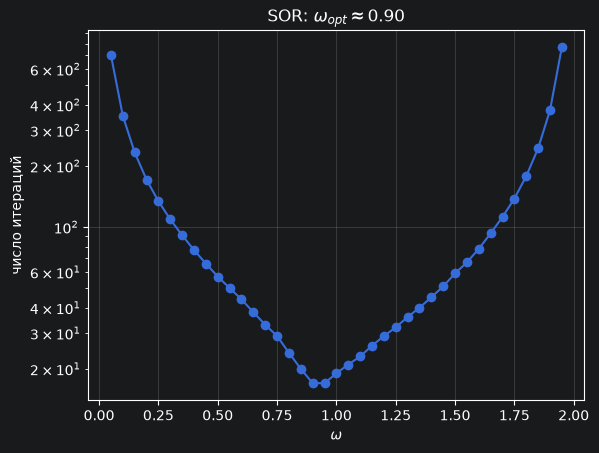

In [42]:
# подбор оптимального w перебором по числу итераций
omegas = np.linspace(0.05, 1.95, 39)
iters = [len(sor(A, f, w, max_iter=1000)[1]) - 1 for w in omegas]
w_opt = omegas[np.argmin(iters)]

plt.semilogy(omegas, iters, "o-")
plt.xlabel(r"$\omega$")
plt.ylabel("число итераций")
plt.title(rf"SOR: $\omega_{{opt}} \approx {w_opt:.2f}$")
plt.grid(alpha=0.3)
save("sor_omega")
plt.show()

results[f"SOR, ω = {w_opt:.2f}"] = sor(A, f, w_opt)

## 6. Градиентный спуск
$$r^k = f - Ax^k,\qquad \tau_k = \frac{(r^k, r^k)}{(Ar^k, r^k)},\qquad x^{k+1} = x^k + \tau_k r^k$$

In [43]:
def gradient_descent(A, f, max_iter=MAX_ITER):
    x = np.zeros(len(f))  # x^0 = 0
    res = [residual(x)]
    for _ in range(max_iter):
        r = f - A @ x  # невязка = антиградиент
        x_new = x + (r @ r) / (r @ A @ r) * r  # шаг tau_k
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["Град. спуск"] = gradient_descent(A, f)

## 7. Метод минимальных невязок
$$\tau_k = \frac{(Ar^k, r^k)}{(Ar^k, Ar^k)},\qquad x^{k+1} = x^k + \tau_k r^k$$

In [44]:
def min_residual(A, f, max_iter=MAX_ITER):
    x = np.zeros(len(f))  # x^0 = 0
    res = [residual(x)]
    for _ in range(max_iter):
        r = f - A @ x
        Ar = A @ r
        x_new = x + (Ar @ r) / (Ar @ Ar) * r  # tau_k минимизирует ||r^{k+1}||
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["Мин. невязки"] = min_residual(A, f)

## 8. Метод сопряжённых градиентов
$$\alpha_k = \frac{(r^k, r^k)}{(Ap^k, p^k)},\quad x^{k+1} = x^k + \alpha_k p^k,\quad r^{k+1} = r^k - \alpha_k Ap^k,$$
$$\beta_k = \frac{(r^{k+1}, r^{k+1})}{(r^k, r^k)},\quad p^{k+1} = r^{k+1} + \beta_k p^k,\qquad p^0 = r^0.$$

In [45]:
def cg(A, f, max_iter=MAX_ITER):
    x = np.zeros(len(f))
    r = f - A @ x
    p = r.copy()  # первое направление — по невязке
    res = [residual(x)]
    for _ in range(max_iter):
        Ap = A @ p
        alpha = (r @ r) / (Ap @ p)
        x_new = x + alpha * p
        r_new = r - alpha * Ap
        p = r_new + (r_new @ r_new) / (r @ r) * p  # новое A-сопряжённое направление
        r = r_new
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["CG"] = cg(A, f)

## 9. Стабилизированный метод бисопряжённых градиентов (BiCGStab)
Не требует симметричности. $\hat r = r^0$, $p^0 = r^0$:
$$v = Ap,\ \ \alpha = \frac{(\hat r, r)}{(\hat r, v)},\ \ s = r - \alpha v,\ \ t = As,\ \ \omega = \frac{(t, s)}{(t, t)},$$
$$x \leftarrow x + \alpha p + \omega s,\quad r_{new} = s - \omega t,\quad \beta = \frac{(\hat r, r_{new})}{(\hat r, r)}\cdot\frac{\alpha}{\omega},\quad p \leftarrow r_{new} + \beta(p - \omega v).$$

In [46]:
def bicgstab(A, f, max_iter=MAX_ITER):
    x = np.zeros(len(f))
    r = f - A @ x
    r_hat, p = r.copy(), r.copy()  # r_hat — фиксированный «теневой» вектор
    res = [residual(x)]
    for _ in range(max_iter):
        v = A @ p
        alpha = (r_hat @ r) / (r_hat @ v)
        s = r - alpha * v
        t = A @ s
        omega = (t @ s) / (t @ t)  # стабилизирующий шаг, минимизирует ||s - omega t||
        x_new = x + alpha * p + omega * s
        r_new = s - omega * t
        beta = (r_hat @ r_new) / (r_hat @ r) * alpha / omega
        p = r_new + beta * (p - omega * v)
        r = r_new
        res.append(residual(x_new))
        # критерий останова
        if norm(x_new - x) < EPS:
            return x_new, res
        x = x_new
    return x, res

results["BiCGStab"] = bicgstab(A, f)

## Результаты

In [47]:
print(f"{'Метод':<22}{'итераций':>9}{'невязка':>12}")
print(f"{'Гаусс':<22}{'—':>9}{residual(x_gauss):>12.2e}")
print(f"{'LU':<22}{'—':>9}{residual(x_lu):>12.2e}")
for name, (x, res) in results.items():
    print(f"{name:<22}{len(res) - 1:>9}{res[-1]:>12.2e}")

print("\nx =")
print(x_gauss.reshape(-1, 1))

Метод                  итераций     невязка
Гаусс                         —    5.19e-17
LU                            —    9.71e-17
Якоби                       300    1.56e+06
Зейдель                      19    8.74e-14
SOR, ω = 0.90                17    2.94e-14
Град. спуск                  37    3.81e-13
Мин. невязки                 33    6.52e-13
CG                           10    5.93e-16
BiCGStab                      7    4.81e-16

x =
[[ 9.190771e-01]
 [ 1.755402e-01]
 [ 6.393482e-02]
 [ 2.727476e-02]
 [ 1.142347e-02]
 [ 3.510839e-03]
 [-7.899578e-04]
 [-3.250801e-03]
 [-4.697878e-03]
 [-5.553740e-03]]


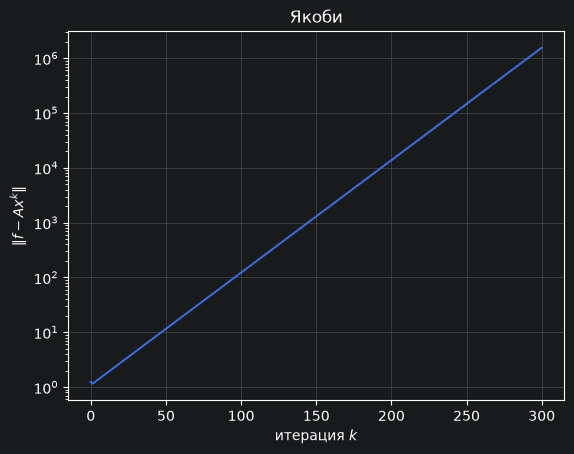

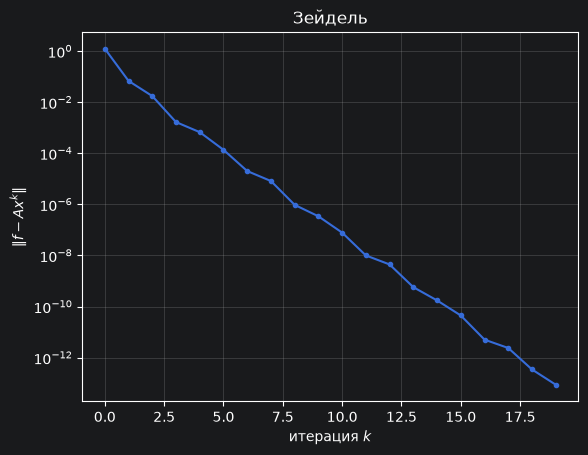

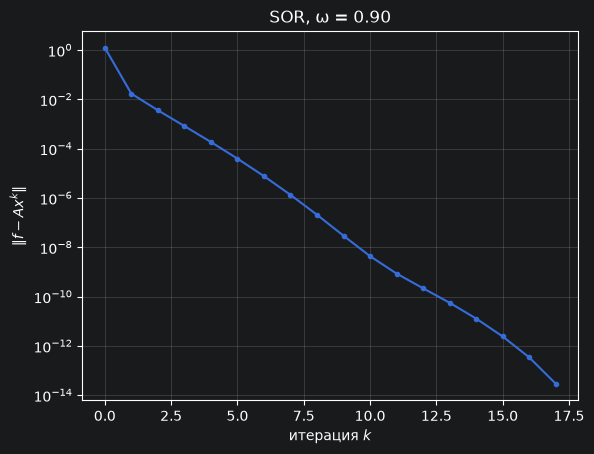

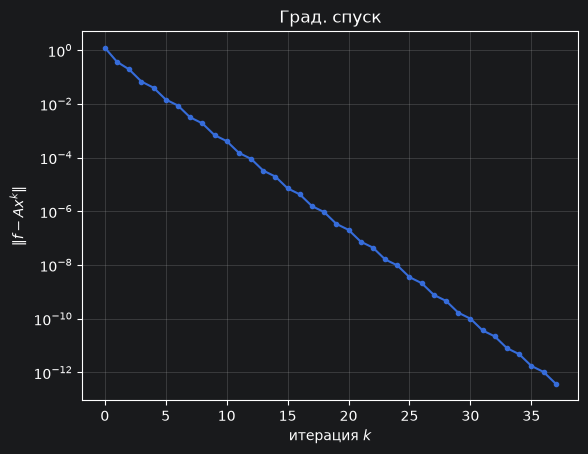

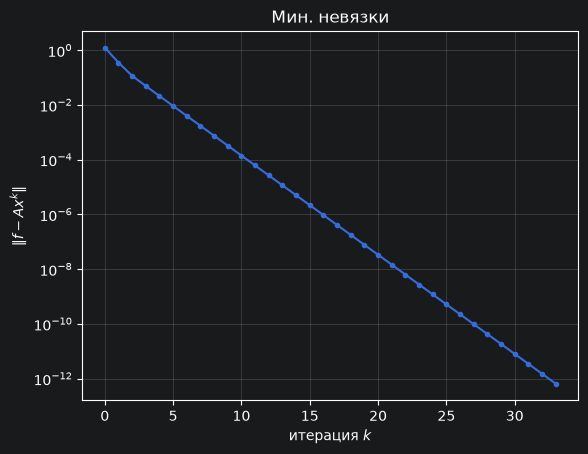

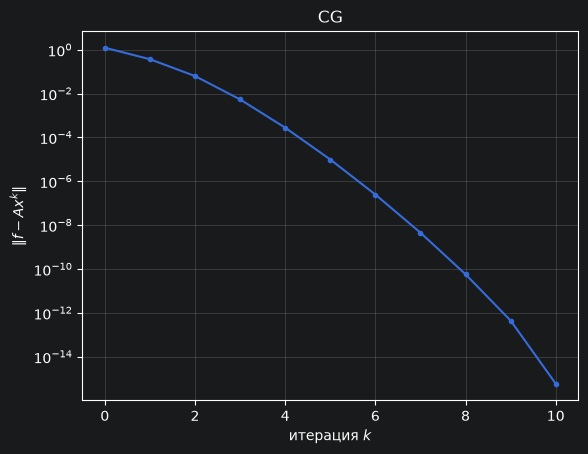

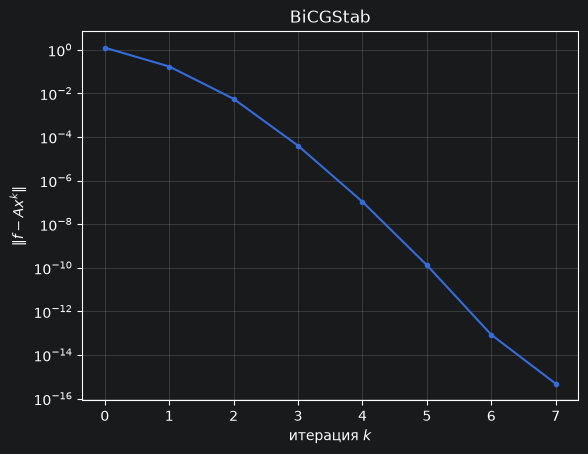

In [32]:
# имена файлов для графиков отдельных методов
FILE = {"Якоби": "jacobi", "Зейдель": "seidel", "SOR": "sor", "Град": "gradient_descent",
        "Мин": "min_residual", "CG": "cg", "BiCG": "bicgstab"}

def file_name(name):
    return next(v for k, v in FILE.items() if name.startswith(k))

# отдельный график невязки для каждого метода
for name, (x, res) in results.items():
    plt.semilogy(res, "o-" if len(res) < 300 else "-", ms=3)
    plt.xlabel("итерация $k$")
    plt.ylabel(r"$\|f - Ax^k\|$")
    plt.title(name)
    plt.grid(alpha=0.3)
    save("residual_" + file_name(name))
    plt.show()

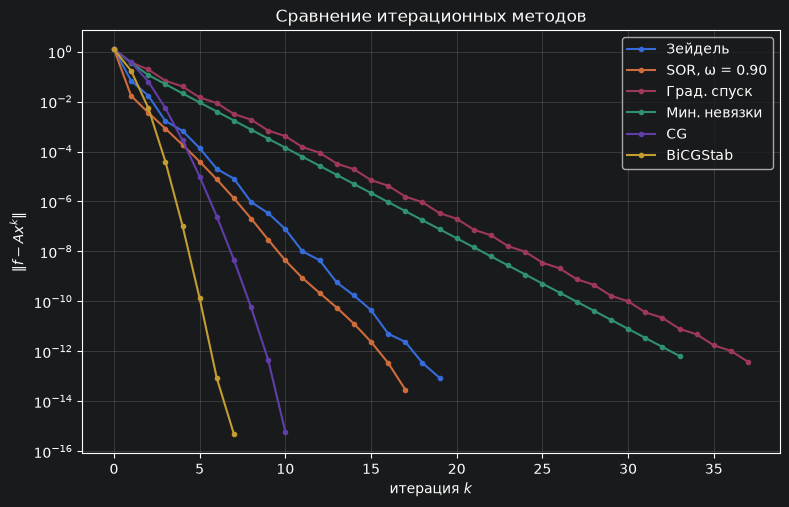

In [33]:
# общий график; расходящиеся методы не рисуем
plt.figure(figsize=(9, 5.5))
for name, (x, res) in results.items():
    if res[-1] < res[0]:
        plt.semilogy(res, "o-" if len(res) < 300 else "-", ms=3, label=name)
plt.xlabel("итерация $k$")
plt.ylabel(r"$\|f - Ax^k\|$")
plt.title("Сравнение итерационных методов")
plt.legend()
plt.grid(alpha=0.3)
save("comparison")
plt.show()

## Выводы

* $A$ симметрична и положительно определена, $\operatorname{cond}_2 A \approx 3.1$; Гаусс и LU дают невязку $\sim10^{-16}$.
* Диагонального преобладания нет, $\rho(B_J) \approx 1.05 > 1$ — **Якоби расходится**.
* $\rho(B_S) \approx 0.22$ — Зейдель сходится за 19 итераций; SOR при $\omega_{opt} \approx 0.9$ — за 17.
* Градиентный спуск (37) и минимальные невязки (33) — линейная сходимость со скоростью $\sim\frac{\kappa-1}{\kappa+1}$.
* CG сходится за $n = 10$ шагов, BiCGStab — за 7.